In [1]:
import pandas as pd

# On vérifie d'abord que Python voit bien le dossier et le fichier
import os
print("Le fichier existe :", os.path.exists("data/logs_reseau.csv"))

# On charge le fichier
df = pd.read_csv("data/logs_reseau.csv")

# On affiche le tableau
df.head()

Le fichier existe : True


,timestamp,src_ip,dst_ip,dst_port,protocol,bytes_sent,duration_s,device_type,action
0,2026-10-05 00:05:13,192.168.1.30,10.0.0.6,80,TCP,7257.0,0.63,capteur_IoT,ALLOW
1,2026-10-05 00:05:43,192.168.1.10,10.0.0.5,80,TCP,1720.0,1.62,capteur_IoT,ALLOW
2,2026-10-05 00:10:45,192.168.1.26,1.1.1.1,1883,TCP,6951.0,4.22,camera_IoT,ALLOW
3,2026-10-05 00:12:25,192.168.1.13,10.0.0.6,80,TCP,3144.0,0.16,capteur_IoT,ALLOW
4,2026-10-05 00:12:34,192.168.1.15,10.0.0.5,8080,TCP,879.0,2.71,serveur,ALLOW


In [2]:
# 1. Combien y a-t-il de lignes et de colonnes ?
print("Dimensions (lignes, colonnes) :", df.shape)

# 2. Y a-t-il des valeurs manquantes ?
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

# 3. Y a-t-il des doublons exacts dans le fichier ?
print("\nNombre de doublons exacts :", df.duplicated().sum())

Dimensions (lignes, colonnes) : (5500, 9)

Valeurs manquantes par colonne :
timestamp        0
src_ip           0
dst_ip           0
dst_port         0
protocol         0
bytes_sent     166
duration_s       0
device_type      0
action           0
dtype: int64

Nombre de doublons exacts : 60


In [3]:
# 1. Supprimer les doublons exacts
df = df.drop_duplicates()

# 2. Mettre protocol en MAJUSCULES
df["protocol"] = df["protocol"].str.upper()

# 3. Remplacer les bytes_sent manquants par la médiane (calculée APRES le dédoublonnage)
mediane = df["bytes_sent"].median()
df["bytes_sent"] = df["bytes_sent"].fillna(mediane)

print("Nettoyage terminé !")
print("Nouvelle taille des données :", df.shape)
print("Il reste", df.isna().sum().sum(), "valeurs manquantes au total.")

Nettoyage terminé !
Nouvelle taille des données : (5440, 9)
Il reste 0 valeurs manquantes au total.


In [4]:
import json

# On calcule les 5 résultats clés
resultats = {
    "nb_connexions_total": int(len(df)),
    "top_port_destination": int(df["dst_port"].value_counts().idxmax()),
    "repartition_actions": df["action"].value_counts().to_dict(),
    "type_appareil_le_plus_actif": str(df["device_type"].value_counts().idxmax()),
    "ip_source_la_plus_bloquee": str(df[df["action"] == "DENY"]["src_ip"].value_counts().idxmax())
}

# On affiche les résultats pour les voir
for cle, valeur in resultats.items():
    print(f"{cle} : {valeur}")

# On sauvegarde dans le fichier resultats.json
with open("resultats.json", "w", encoding="utf-8") as f:
    json.dump(resultats, f, indent=4, ensure_ascii=False)

print("\n✅ Fichier 'resultats.json' créé avec succès !")

nb_connexions_total : 5440
top_port_destination : 443
repartition_actions : {'ALLOW': 4702, 'DENY': 738}
type_appareil_le_plus_actif : capteur_IoT
ip_source_la_plus_bloquee : 192.168.1.99

✅ Fichier 'resultats.json' créé avec succès !


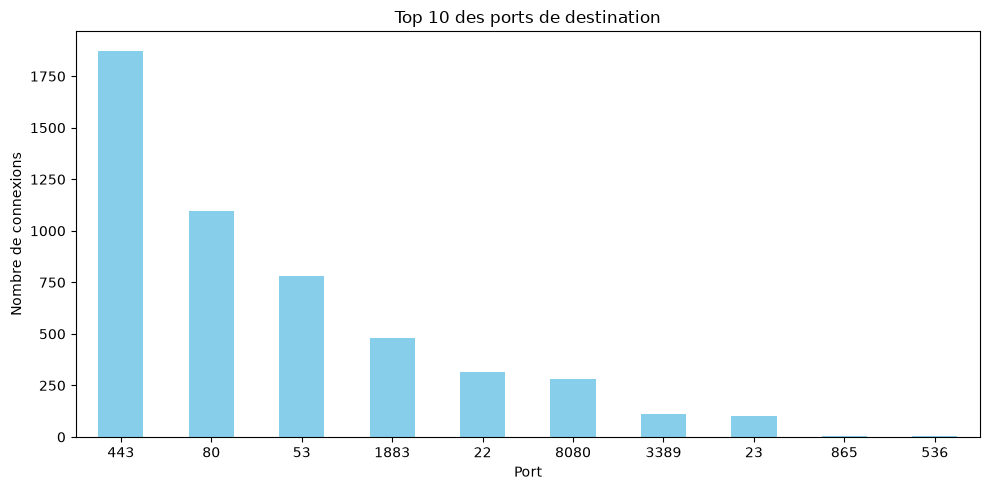

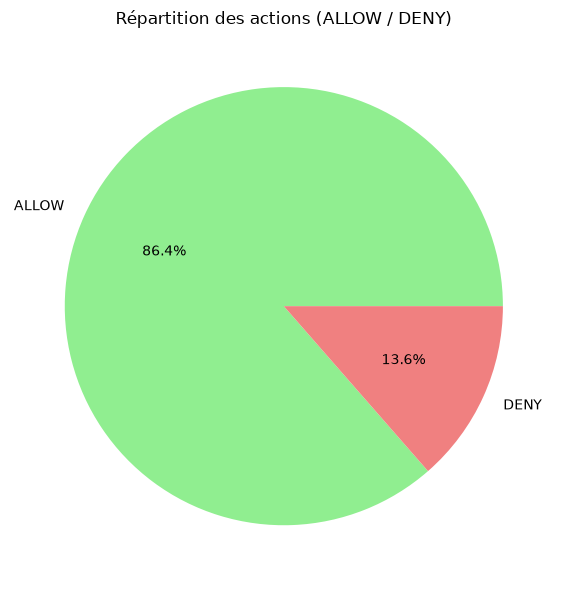

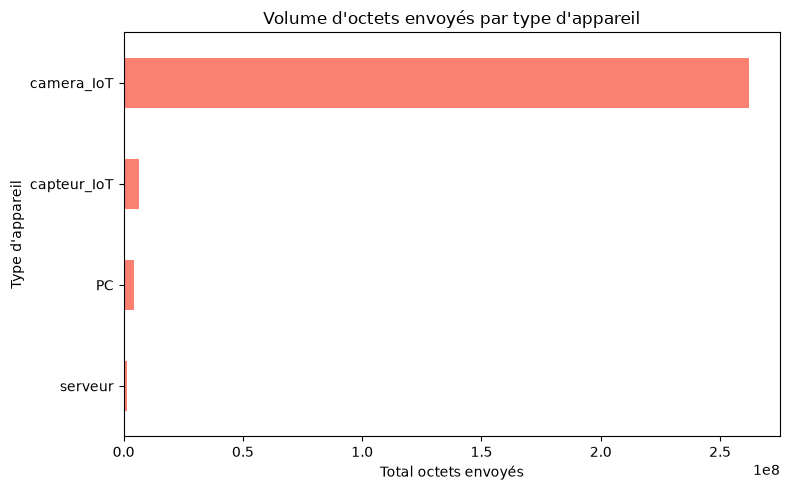

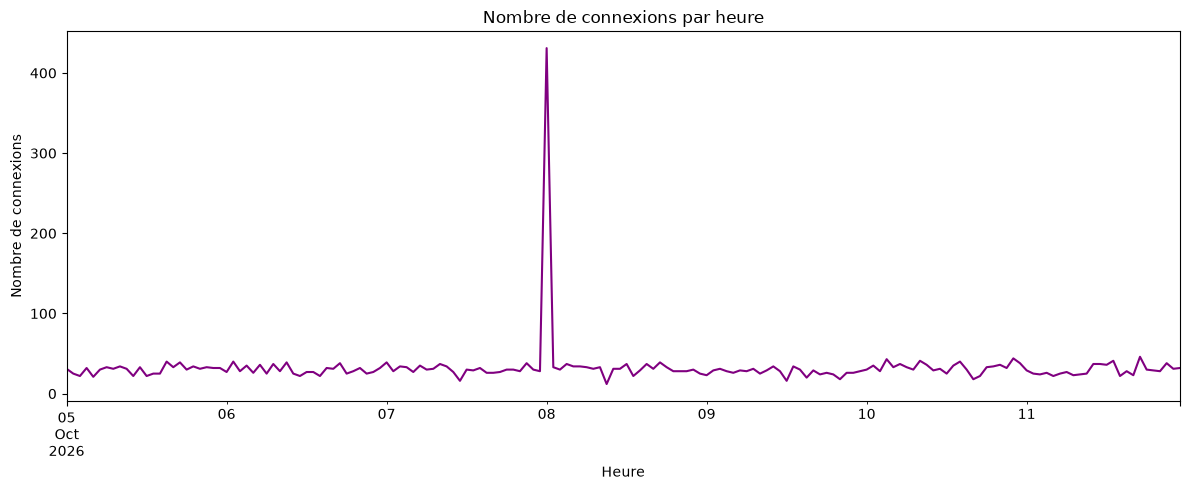

✅ Les 4 figures ont été enregistrées dans le dossier 'figures' !


In [6]:
import matplotlib.pyplot as plt

# --- Figure 1 : Top 10 des ports ---
plt.figure(figsize=(10, 5))
df['dst_port'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 des ports de destination')
plt.xlabel('Port')
plt.ylabel('Nombre de connexions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('figures/top_ports.png')
plt.show()
plt.close()

# --- Figure 2 : Répartition ALLOW / DENY ---
plt.figure(figsize=(6, 6))
df['action'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightgreen', 'lightcoral'])
plt.title('Répartition des actions (ALLOW / DENY)')
plt.ylabel('') # Pour enlever le texte moche sur le côté
plt.tight_layout()
plt.savefig('figures/allow_deny.png')
plt.show()
plt.close()

# --- Figure 3 : Volume par type d'appareil ---
plt.figure(figsize=(8, 5))
df.groupby('device_type')['bytes_sent'].sum().sort_values().plot(kind='barh', color='salmon')
plt.title("Volume d'octets envoyés par type d'appareil")
plt.xlabel('Total octets envoyés')
plt.ylabel("Type d'appareil")
plt.tight_layout()
plt.savefig('figures/bytes_device.png')
plt.show()
plt.close()

# --- Figure 4 : Connexions par heure ---
# On convertit d'abord le timestamp en vraie date
df['timestamp'] = pd.to_datetime(df['timestamp'])
plt.figure(figsize=(12, 5))
df.set_index('timestamp').resample('h').size().plot(color='purple')
plt.title('Nombre de connexions par heure')
plt.xlabel('Heure')
plt.ylabel('Nombre de connexions')
plt.tight_layout()
plt.savefig('figures/connexions_heure.png')
plt.show()
plt.close()

print("✅ Les 4 figures ont été enregistrées dans le dossier 'figures' !")